
# Superstore Retail Sales Analysis
## Exploratory Data Analysis (EDA)

**Internship Role:** Data Analytics & Power BI

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Google Colab


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!



## 1. Introduction

This project analyzes Superstore retail sales data to identify sales trends, customer behaviour, product performance, and profitability.


In [2]:

from google.colab import files

uploaded = files.upload()

df = pd.read_csv('superstore_sales.csv')

print(df.head())


Saving superstore_sales.csv to superstore_sales.csv
  Row ID        Order ID  Order Date   Ship Date       Ship Mode Customer ID  \
0      1  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
1      2  CA-2017-152156   11/8/2017  11/11/2017    Second Class    CG-12520   
2      3  CA-2017-138688   6/12/2017   6/16/2017    Second Class    DV-13045   
3      4  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   
4      5  US-2016-108966  10/11/2016  10/18/2016  Standard Class    SO-20335   

     Customer Name    Segment        Country             City  ...  \
0      Claire Gute   Consumer  United States        Henderson  ...   
1      Claire Gute   Consumer  United States        Henderson  ...   
2  Darrin Van Huff  Corporate  United States      Los Angeles  ...   
3   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   
4   Sean O'Donnell   Consumer  United States  Fort Lauderdale  ...   

  Postal Code  Region       Product ID        


## 2. Dataset Description

- Total Records: 9,994
- Total Columns: 21
- Dataset Type: Retail Sales

**Important Columns:**
- Order Date
- Customer Segment
- Product Category
- Sales
- Quantity
- Discount
- Profit



## 3. Data Cleaning and Preprocessing

- Checked missing values and duplicates.
- Removed 806 invalid records.
- Converted date columns into datetime format.
- Identified 11 missing Postal Code values.

**Final Dataset:** 9,994 rows and 21 columns.


In [3]:

# Check dataset information
print("Dataset Shape:", df.shape)

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

# Check column information
print("\nDataset Information:")
df.info()


Dataset Shape: (10800, 21)

Missing Values:
Row ID             0
Order ID           0
Order Date       806
Ship Date        806
Ship Mode        806
Customer ID      806
Customer Name    806
Segment          806
Country          806
City             806
State            806
Postal Code      817
Region           806
Product ID       806
Category         806
Sub-Category     806
Product Name     806
Sales            806
Quantity         806
Discount         806
Profit           806
dtype: int64

Duplicate Records: 504

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   obj

In [4]:

# Remove rows without Order Date
df = df.dropna(subset=['Order Date']).copy()

# Convert dates into datetime format
df['Order Date'] = pd.to_datetime(df['Order Date'])

df['Ship Date'] = pd.to_datetime(df['Ship Date'])

# Check missing values again
print("Cleaned Dataset Shape:", df.shape)

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())


Cleaned Dataset Shape: (9994, 21)

Missing Values After Cleaning:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64



## 4. Monthly Sales Analysis

Analyzed monthly sales to identify trends and seasonal patterns.

A line chart was created to visualize monthly sales fluctuations.


In [5]:

# Extract year and month
df['Year-Month'] = df['Order Date'].dt.to_period('M')

# Calculate monthly sales
monthly_sales = df.groupby('Year-Month')['Sales'].sum()

# Display monthly sales
print(monthly_sales)


Year-Month
2015-01     14236.8950
2015-02      4519.8920
2015-03     55691.0090
2015-04     28295.3450
2015-05     23648.2870
2015-06     34595.1276
2015-07     33946.3930
2015-08     27909.4685
2015-09     81777.3508
2015-10     31453.3930
2015-11     78628.7167
2015-12     69545.6205
2016-01     18174.0756
2016-02     11951.4110
2016-03     38726.2520
2016-04     34195.2085
2016-05     30131.6865
2016-06     24797.2920
2016-07     28765.3250
2016-08     36898.3322
2016-09     64595.9180
2016-10     31404.9235
2016-11     75972.5635
2016-12     74919.5212
2017-01     18542.4910
2017-02     22978.8150
2017-03     51715.8750
2017-04     38750.0390
2017-05     56987.7280
2017-06     40344.5340
2017-07     39261.9630
2017-08     31115.3743
2017-09     73410.0249
2017-10     59687.7450
2017-11     79411.9658
2017-12     96999.0430
2018-01     43971.3740
2018-02     20301.1334
2018-03     58872.3528
2018-04     36521.5361
2018-05     44261.1102
2018-06     52981.7257
2018-07     45264.4160


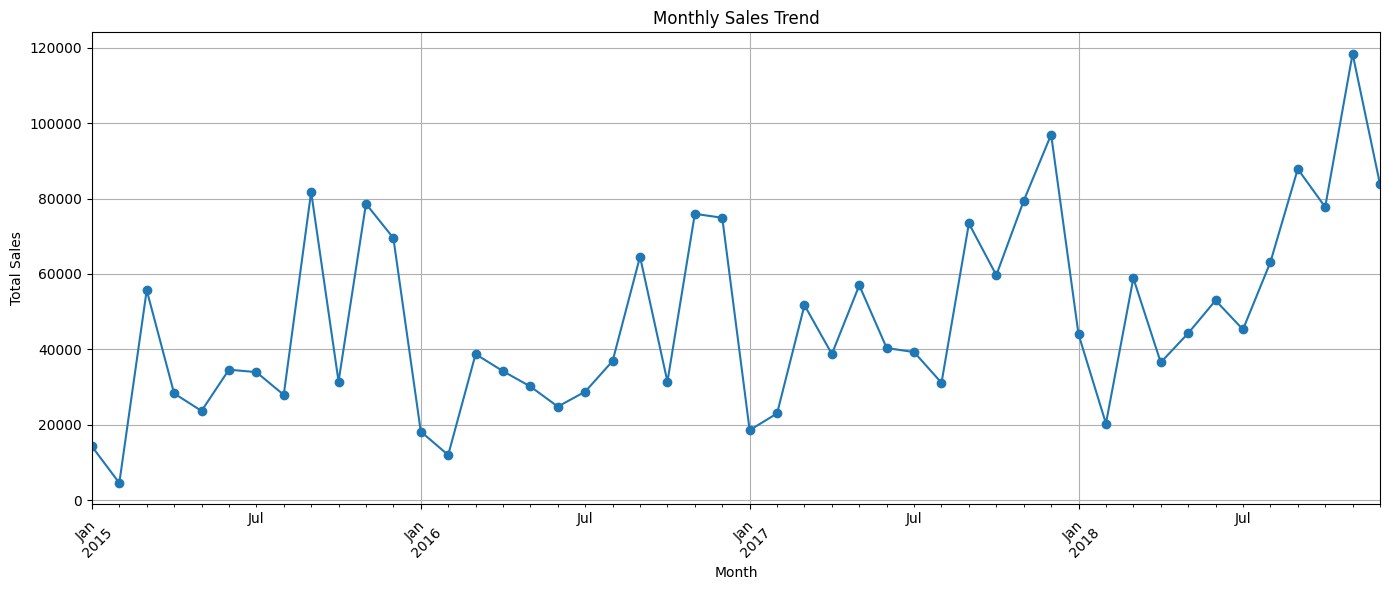

In [6]:

plt.figure(figsize=(14, 6))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()



## 5. Customer Segment Analysis

Analyzed sales, orders, and quantities across three customer segments:

- Consumer
- Corporate
- Home Office

A bar chart was used to compare their sales.


In [7]:

# Analyze customer segments
customer_analysis = df.groupby('Segment').agg(
    Total_Orders=('Order ID', 'nunique'),
    Total_Sales=('Sales', 'sum'),
    Total_Quantity=('Quantity', 'sum')
)

print(customer_analysis)


             Total_Orders   Total_Sales  Total_Quantity
Segment                                                
Consumer             2586  1.161401e+06         19521.0
Corporate            1514  7.061464e+05         11608.0
Home Office           909  4.296531e+05          6744.0


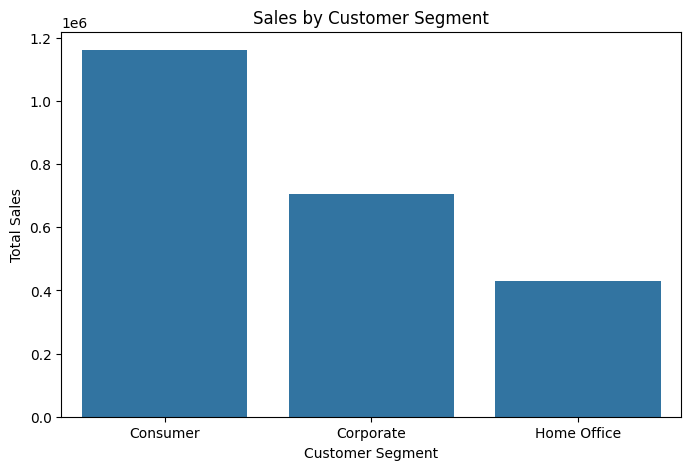

In [8]:

plt.figure(figsize=(8, 5))

sns.barplot(
    x=customer_analysis.index,
    y=customer_analysis['Total_Sales']
)

plt.title('Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')
plt.show()



## 6. Category-wise Sales and Profit Analysis

Analyzed the performance of three product categories:

- Furniture
- Office Supplies
- Technology

Compared total sales and profit using a bar chart.


In [9]:

category_analysis = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
)

print(category_analysis)


                 Total_Sales  Total_Profit  Total_Quantity
Category                                                  
Furniture        741999.7953    18451.2728          8028.0
Office Supplies  719047.0320   122490.8008         22906.0
Technology       836154.0330   145454.9481          6939.0



## 9. Conclusion

The analysis identified important sales trends, customer patterns, and product performance.

The findings can help businesses improve sales strategies, manage discounts, and increase profitability.


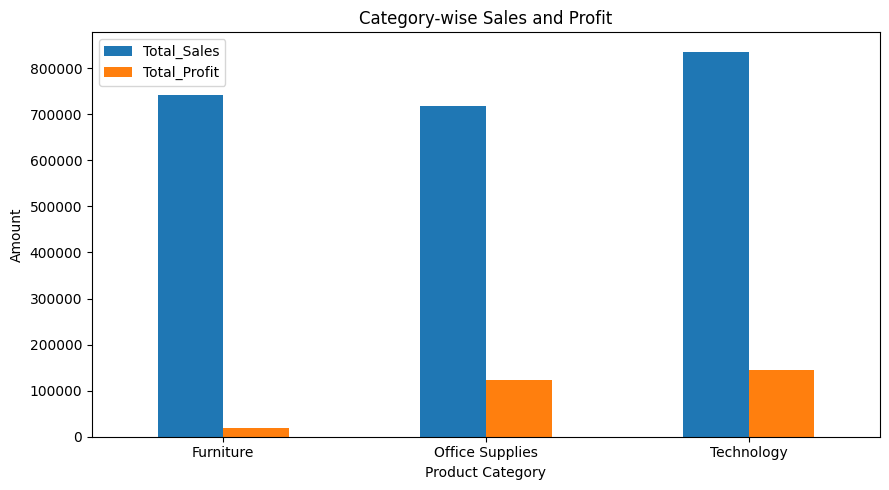

In [10]:

category_analysis[['Total_Sales', 'Total_Profit']].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Category-wise Sales and Profit')
plt.xlabel('Product Category')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



## 7. Discount Sensitivity Analysis

Analyzed the relationship between discounts and profitability.

A scatter plot was created to understand how different discount levels relate to profit.


In [11]:

# Analyze discount and profit
discount_analysis = df.groupby('Discount').agg(
    Average_Profit=('Profit', 'mean'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
)

print(discount_analysis.round(2))


          Average_Profit  Total_Sales  Total_Profit
Discount                                           
0.00               66.90   1087908.47     320987.60
0.10               96.06     54369.35       9029.18
0.15               27.29     27558.52       1418.99
0.20               24.70    764594.37      90337.31
0.30              -45.68    103226.66     -10369.28
0.32              -88.56     14493.46      -2391.14
0.40             -111.93    116417.78     -23057.05
0.45             -226.65      5484.97      -2493.11
0.50             -310.70     58918.54     -20506.43
0.60              -43.08      6644.70      -5944.66
0.70              -95.87     40620.28     -40075.36
0.80             -101.80     16963.76     -30539.04


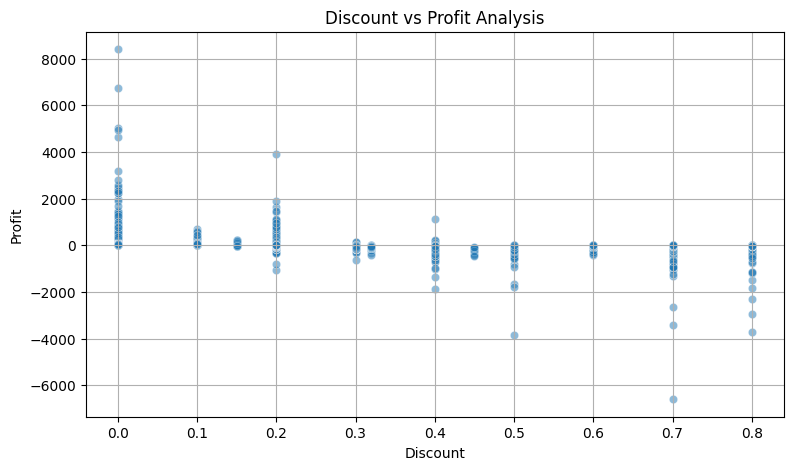

In [12]:

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    alpha=0.5
)

plt.title('Discount vs Profit Analysis')
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.grid(True)
plt.show()


In [13]:

print("Total Sales:", round(df['Sales'].sum(), 2))
print("Total Profit:", round(df['Profit'].sum(), 2))
print("Total Orders:", df['Order ID'].nunique())
print("Total Customers:", df['Customer ID'].nunique())
print("Average Discount:", round(df['Discount'].mean(), 2))
print("Average Order Value:", round(
    df.groupby('Order ID')['Sales'].sum().mean(), 2
))


Total Sales: 2297200.86
Total Profit: 286397.02
Total Orders: 5009
Total Customers: 793
Average Discount: 0.16
Average Order Value: 458.61



## 8. Executive Business Findings

1. Consumer customers generated the highest sales.
2. Technology was the most profitable category.
3. November 2018 recorded the highest monthly sales.
4. Higher discounts were generally associated with lower profitability.
5. Total business sales reached approximately $2.30 million.



## 9. Conclusion

The analysis identified important sales trends, customer patterns, and product performance.

The findings can help businesses improve sales strategies, manage discounts, and increase profitability.
